# فصل ششم — آزمایشگاه بازتولیدپذیر

تمام داده‌ها ساختگی‌اند. فایل‌های CSV و JSON باید در کنار Notebook باشند؛ هستهٔ Python 3 از برنامهٔ آموزشی مستقل استفاده می‌کند.

In [1]:
from chapter06_examples import (load_sequences, load_graphs, seq_support, basket_support,
    subsequence_match, prefixspan_singletons, exhaustive_singletons,
    taxonomy_projection, graph_support, fisher_enrichment_upper)
S=load_sequences(); G=load_graphs()
print("Customers:",len(S),"Independent graphs:",len(G))

Customers: 8 Independent graphs: 6


## ۱. سبد، ترتیب، هم‌زمانی؛ سه پرسش متفاوت

In [2]:
p=[{"bread"},{"milk"}]
print("Basket",basket_support(S,{"bread","milk"}))
print("Ordered",seq_support(S,p))
print("One event",seq_support(S,[{"bread","milk"}]))
assert (basket_support(S,{"bread","milk"})[0],seq_support(S,p)[0],seq_support(S,[{"bread","milk"}])[0])==(7,5,1)

Basket (7, ['S1', 'S2', 'S3', 'S4', 'S5', 'S6', 'S7'])
Ordered (5, ['S1', 'S3', 'S4', 'S5', 'S7'])
One event (1, ['S2'])


## ۲. پشتیبانی تحت قیدهای مختلف

In [3]:
for label,kw in [("none",{}),("adjacent",{"max_gap":0}),("within one day",{"max_span_days":1})]:
    print(label,seq_support(S,p,**kw))

none (5, ['S1', 'S3', 'S4', 'S5', 'S7'])
adjacent (4, ['S1', 'S3', 'S4', 'S7'])
within one day (2, ['S3', 'S7'])


## ۳. شمارش الگوهای پرپشتیبان با PrefixSpan محدود

In [4]:
found=prefixspan_singletons(S,min_count=3,max_len=3)
for pattern,count in sorted(found.items()):print(" > ".join(pattern),count)

bread 7
bread > coffee 5
bread > milk 5
bread > tea 5
coffee 7
coffee > milk 3
coffee > tea 4
milk 8
milk > coffee 3
milk > tea 3
tea 6


## ۴. کنترل با شمارش مستقلِ فراگیر

In [5]:
brute=exhaustive_singletons(S,3,3)
assert found==brute
print("Verified patterns:",len(found))

Verified patterns: 11


## ۵. رخدادهای چندقلمی

In [6]:
print("milk+tea in same event:",seq_support(S,[{"milk","tea"}]))
print("milk then tea (strictly later):",seq_support(S,[{"milk"},{"tea"}]))

milk+tea in same event: (2, ['S4', 'S7'])
milk then tea (strictly later): (3, ['S1', 'S2', 'S3'])


## ۶. سلسله‌مراتب مفهوم

In [7]:
P=taxonomy_projection(S,{"coffee":"beverage","tea":"beverage"})
print("beverage customer support:",seq_support(P,[{"beverage"}]))

beverage customer support: (8, ['S1', 'S2', 'S3', 'S4', 'S5', 'S6', 'S7', 'S8'])


## ۷. زیرگراف برچسب‌دار: یال، مسیر، مثلث

In [8]:
patterns={"AB":{"nodes":{"u":"A","v":"B"},"edges":[["u","v"]]},
 "ABC path":{"nodes":{"u":"A","v":"B","w":"C"},"edges":[["u","v"],["v","w"]]},
 "ABC triangle":{"nodes":{"u":"A","v":"B","w":"C"},"edges":[["u","v"],["v","w"],["u","w"]]}}
for name,p in patterns.items():print(name,graph_support(G,p))

AB (5, ['G1', 'G2', 'G3', 'G4', 'G5'])
ABC path (3, ['G1', 'G2', 'G5'])
ABC triangle (1, ['G1'])


## ۸. رابطهٔ منفی و مقدار مورد انتظار

In [9]:
N,a,b,both=8,4,5,1
expected=a*b/N
print("Observed",both,"Expected under independence",expected)
print("Hypergeometric upper-tail P(X >= 1)",fisher_enrichment_upper(N,both,a,b))
print("Note: this is NOT a test of negative association; use an appropriate lower tail.")

Observed 1 Expected under independence 2.5
Hypergeometric upper-tail P(X >= 1) 1.0
Note: this is NOT a test of negative association; use an appropriate lower tail.


## ۹. پایداری در گروه‌های جداگانه

In [10]:
first={k:v for k,v in S.items() if k in ("S1","S2","S3","S4")}
second={k:v for k,v in S.items() if k in ("S5","S6","S7","S8")}
for k,p in [("B>M",[{"bread"},{"milk"}]),("M>C",[{"milk"},{"coffee"}])]:
    print(k,seq_support(first,p)[0],seq_support(second,p)[0])

B>M 3 2
M>C 1 2


## ۱۰. بازنمایی تصویری ساده؛ نمودار آماری نه تزئینی

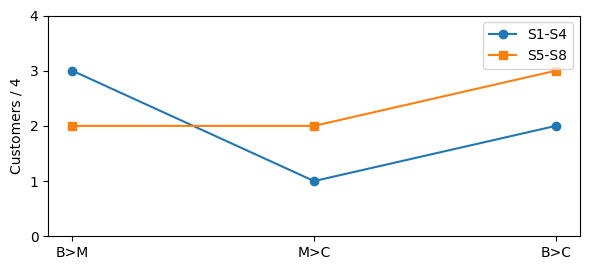

In [11]:
import matplotlib.pyplot as plt
words=[([{"bread"},{"milk"}]),([{"milk"},{"coffee"}]),([{"bread"},{"coffee"}])]
left=[seq_support(first,p)[0] for p in words]; right=[seq_support(second,p)[0] for p in words]
plt.figure(figsize=(6,2.8)); plt.plot([0,1,2],left,"o-",label="S1-S4");plt.plot([0,1,2],right,"s-",label="S5-S8")
plt.xticks([0,1,2],["B>M","M>C","B>C"]);plt.ylim(0,4);plt.ylabel("Customers / 4");plt.legend();plt.tight_layout();plt.show()

## ۱۱. اجرای آزمون‌های پیاده‌سازی

In [12]:
import unittest
import test_chapter06_examples
suite=unittest.defaultTestLoader.loadTestsFromModule(test_chapter06_examples)
result=unittest.TextTestRunner(verbosity=0).run(suite)
assert result.wasSuccessful()
print("Tests passed:",result.testsRun)

----------------------------------------------------------------------
Ran 26 tests in 0.008s

OK


Tests passed: 26


**نتیجه‌گیری:** این آزمایشگاه، روش‌شناسی محاسبهٔ پشتیبانی را آموزش می‌دهد؛ کد PrefixSpan فقط S-extension تک‌قلمی و کد زیرگراف، تطبیق نمایی برای گراف‌های کوچک را انجام می‌دهند.